# Caso 3: Recomendador de artículos con NMF y similitud de coseno
**Actividad 05 · Aprendizaje de Máquina · UNAP**

Escenario: somos el equipo de Machine Learning de un periódico en línea. Dado el artículo que un lector
está leyendo, hay que recomendar otros con temas parecidos.

Idea:
1. Convertir los artículos a TF-IDF.
2. Aplicar NMF: cada artículo queda descrito por la mezcla de *temas* que contiene.
3. Normalizar esas mezclas y comparar artículos con similitud de coseno.
4. Medir qué tan buenas son las recomendaciones frente a usar TF-IDF directo.

In [1]:
import os, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
from sklearn.preprocessing import normalize

SEED = 42
os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados", exist_ok=True)

## 1. Datos
Usamos el conjunto de entrenamiento de 20 Newsgroups como si fueran los artículos del periódico.
Los títulos salen de la línea `Subject:`; el texto se limpia sin encabezados ni citas.

In [2]:
limpio = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"),
                            shuffle=True, random_state=SEED)
crudo = fetch_20newsgroups(subset="train", shuffle=True, random_state=SEED)  # mismo orden, con encabezados

def titulo(txt):
    m = re.search(r"^Subject:\s*(.+)$", txt, re.M)
    t = m.group(1).strip() if m else "(sin título)"
    t = re.sub(r"^(re:\s*)+", "", t, flags=re.I)
    return t[:70]

textos = np.array(limpio.data, dtype=object)
y = np.array(limpio.target)
nombres = list(limpio.target_names)
titulos = np.array([titulo(t) for t in crudo.data], dtype=object)

ok = np.array([len(t.split()) >= 30 for t in textos])
textos, y, titulos = textos[ok], y[ok], titulos[ok]
print("Artículos:", len(textos), "| temas reales (solo para evaluar):", len(nombres))

Artículos: 9373 | temas reales (solo para evaluar): 20


## 2. TF-IDF

In [3]:
vec = TfidfVectorizer(stop_words="english", max_df=0.5, min_df=5, max_features=8000, sublinear_tf=True)
tfidf = vec.fit_transform(textos)
terminos = vec.get_feature_names_out()
print("Matriz TF-IDF:", tfidf.shape)

Matriz TF-IDF: (9373, 8000)


## 3. Elegir el número de temas
Probamos varios valores de `n_components`. Para medir la calidad usamos *precisión@5*:
de las 5 recomendaciones, qué proporción viene del mismo grupo de noticias que el artículo consultado.
(Es una medida aproximada: dos grupos distintos pueden tratar temas parecidos.)

In [4]:
rng = np.random.RandomState(SEED)
consultas = rng.choice(len(y), 500, replace=False)

def precision_at_5(sim_batch, consultas):
    aciertos = []
    for fila, q in zip(sim_batch, consultas):
        fila = fila.copy(); fila[q] = -np.inf          # no recomendar el mismo artículo
        top = np.argpartition(-fila, 5)[:5]
        aciertos.append((y[top] == y[q]).mean())
    return float(np.mean(aciertos))

cands = [10, 20, 30, 40]
info_k, modelos = {}, {}
for k in cands:
    nmf = NMF(n_components=k, init="nndsvda", random_state=SEED, max_iter=300)
    W = nmf.fit_transform(tfidf)
    Wn = normalize(W)
    p5 = precision_at_5(Wn[consultas] @ Wn.T, consultas)
    info_k[k] = {"error": float(nmf.reconstruction_err_), "p5": p5}
    modelos[k] = (nmf, W)
    print(f"k={k:>2} | error de reconstrucción={nmf.reconstruction_err_:.2f} | precisión@5={p5:.3f}")

k_final = max(info_k, key=lambda k: info_k[k]["p5"])
nmf, W = modelos[k_final]
Wn = normalize(W)
print("k elegido:", k_final)

k=10 | error de reconstrucción=94.65 | precisión@5=0.334


k=20 | error de reconstrucción=93.95 | precisión@5=0.447


E:\unap\aprendizaje de maquina\actividad05\venv\Lib\site-packages\sklearn\decomposition\_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 300 reached. Increase it to improve convergence.
  warnings.warn(


k=30 | error de reconstrucción=93.36 | precisión@5=0.420


k=40 | error de reconstrucción=92.86 | precisión@5=0.441
k elegido: 20


## 4. Los temas descubiertos
Las palabras con más peso ayudan a interpretar cada componente, pero algunos quedan dominados por términos genéricos,
números o una firma repetida. También miramos qué grupo de noticias aporta más a cada componente.

In [5]:
temas = []
for t, comp in enumerate(nmf.components_):
    palabras = [terminos[i] for i in comp.argsort()[::-1][:8]]
    peso_por_grupo = [Wn[y == c, t].mean() for c in range(len(nombres))]
    g = int(np.argmax(peso_por_grupo))
    temas.append({"tema": t, "palabras": palabras, "grupo_dominante": nombres[g]})
pd.DataFrame(temas)

,tema,palabras,grupo_dominante
0,0,"[ve, time, got, just, did, didn, years, ago]",sci.med
1,1,"[card, video, bus, cards, drivers, monitor, dr...",comp.sys.ibm.pc.hardware
2,2,"[geb, dsl, chastity, n3jxp, cadre, shameful, i...",sci.med
3,3,"[game, team, games, players, year, play, seaso...",rec.sport.hockey
4,4,"[government, gun, law, people, state, rights, ...",talk.politics.guns
5,5,"[god, jesus, bible, christians, believe, chris...",soc.religion.christian
6,6,"[sale, offer, shipping, price, condition, inte...",misc.forsale
7,7,"[thanks, advance, know, mail, does, hi, info, ...",comp.graphics
8,8,"[key, chip, encryption, clipper, keys, escrow,...",sci.crypt
9,9,"[israel, israeli, jews, armenian, armenians, t...",talk.politics.mideast


## 5. Recomendador
Normalizamos cada vector de temas (así el producto punto es el coseno) y rankeamos por similitud.

In [6]:
def recomendar(i, n=5):
    sims = Wn @ Wn[i]
    sims[i] = -np.inf
    top = np.argsort(-sims)[:n]
    return pd.DataFrame({"título": titulos[top], "grupo": [nombres[y[j]] for j in top],
                         "similitud": np.round(sims[top], 3)})

def buscar(grupo):
    cand = [i for i in range(len(y)) if nombres[y[i]] == grupo and 80 <= len(textos[i].split()) <= 400
            and titulos[i] != "(sin título)"]
    return cand[0]

ejemplos = []
for g in ["sci.space", "rec.sport.hockey", "comp.graphics"]:
    i = buscar(g)
    r = recomendar(i)
    print(f"\nArtículo: «{titulos[i]}»  [{g}]")
    print(r.to_string(index=False))
    ejemplos.append({"titulo": str(titulos[i]), "grupo": g,
                     "recomendaciones": [{"titulo": str(a), "grupo": b, "similitud": float(c)}
                                         for a, b, c in zip(r["título"], r["grupo"], r["similitud"])]})


Artículo: «nuclear waste»  [sci.space]
                                      título              grupo  similitud
Homeopathy: a respectable medical tradition?            sci.med      0.971
    MORBUS MENIERE - is there a real remedy?            sci.med      0.961
                                    response talk.politics.misc      0.943
                                     jiggers            sci.med      0.940
            Is MSG sensitivity superstition?            sci.med      0.937

Artículo: «NHL Team Captains»  [rec.sport.hockey]
                                                            título              grupo  similitud
                                                 NHL Team Captains   rec.sport.hockey      0.986
ABC's announcers, ESPN's (lack of) coverage (WAS: Re: Atlanta ...)   rec.sport.hockey      0.984
              Don Cherry - Coach's Corner summary - April 19, 1993   rec.sport.hockey      0.983
                                                       Why Spanky? rec.

## 6. Comparación con TF-IDF directo y con azar

precisión@5  NMF: 0.447 | TF-IDF directo: 0.634 | azar: 0.051


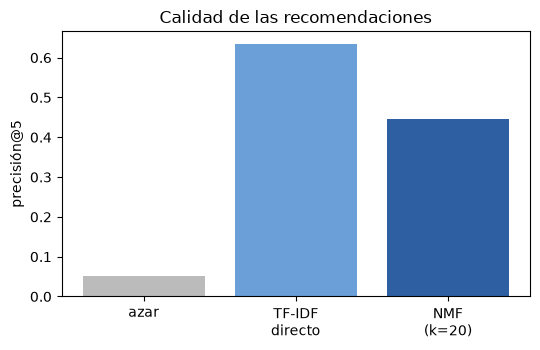

In [7]:
tf_norm = normalize(tfidf)
p5_tfidf = precision_at_5(np.asarray((tf_norm[consultas] @ tf_norm.T).todense()), consultas)
p5_nmf = info_k[k_final]["p5"]
frec = np.bincount(y) / len(y)
p5_azar = float((frec ** 2).sum())
print(f"precisión@5  NMF: {p5_nmf:.3f} | TF-IDF directo: {p5_tfidf:.3f} | azar: {p5_azar:.3f}")

plt.figure(figsize=(5.5, 3.6))
plt.bar(["azar", "TF-IDF\ndirecto", f"NMF\n(k={k_final})"], [p5_azar, p5_tfidf, p5_nmf],
        color=["#bbbbbb", "#6a9fd8", "#2e5fa3"])
plt.ylabel("precisión@5"); plt.title("Calidad de las recomendaciones")
plt.tight_layout(); plt.savefig("figuras/caso3_precision.png", dpi=150); plt.show()

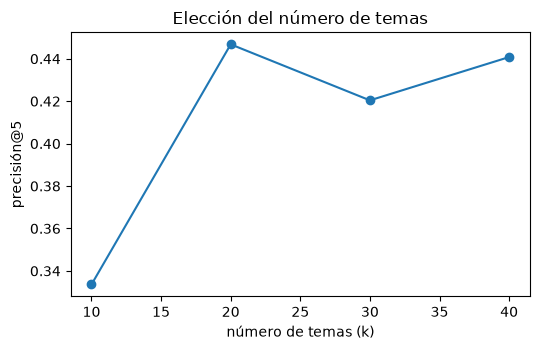

Resultados guardados en resultados/caso3.json


In [8]:
plt.figure(figsize=(5.5, 3.6))
plt.plot(cands, [info_k[k]["p5"] for k in cands], "o-")
plt.xlabel("número de temas (k)"); plt.ylabel("precisión@5")
plt.title("Elección del número de temas")
plt.tight_layout(); plt.savefig("figuras/caso3_k.png", dpi=150); plt.show()

with open("resultados/caso3.json", "w", encoding="utf-8") as f:
    json.dump({
        "n_docs": int(len(y)), "vocab": int(tfidf.shape[1]), "n_consultas": int(len(consultas)),
        "candidatos": {str(k): v for k, v in info_k.items()}, "k": int(k_final),
        "p5_nmf": p5_nmf, "p5_tfidf": p5_tfidf, "p5_azar": p5_azar,
        "temas": temas, "ejemplos": ejemplos,
    }, f, ensure_ascii=False, indent=2)
print("Resultados guardados en resultados/caso3.json")

## Conclusión del caso
- En esta evaluación, TF-IDF directo superó a NMF en precisión@5.
- NMF comprime los artículos en mezclas de temas y permite interpretar parte de las recomendaciones, pero algunos componentes no son claros.
- La precisión@5 usa el grupo de noticias como referencia; dos grupos distintos pueden tratar temas parecidos.